# Clase 1: Introducción al Machine Learning

En este laboratorio vamos a:

1. Ver un ejemplo pequeño de aprendizaje supervisado.
2. Comparar "programar reglas a mano" vs. "dejar que un modelo aprenda".
3. Explorar un dataset real con pandas.
4. Hacer un primer ejercicio de clasificación no supervisada (clustering) muy simple.

El objetivo de este laboratorio no es entender los algoritmos, sino **ver a Machine Learning funcionando**.

## 1. Programar reglas a mano vs. aprender de datos

Supongamos que queremos decidir si un mail es spam o no, mirando cuántas veces aparece la palabra "gratis".

In [1]:
def es_spam_regla(cantidad_veces_gratis):
    return cantidad_veces_gratis >= 3

for veces in [0, 1, 3, 5]:
    print(veces, "->", es_spam_regla(veces))

0 -> False
1 -> False
3 -> True
5 -> True


El problema: **nosotros elegimos el número 3** a ojo. ¿Y si la regla real depende de varias palabras a la vez, o de patrones que no se nos ocurren?

En Machine Learning, en cambio, le damos ejemplos ya etiquetados (mails marcados como spam o no) y dejamos que el algoritmo encuentre el patrón.

In [2]:
import numpy as np

# Puede ser: [cantidad de veces que aparece la palabra "gratis", cantidad de links del mail]
X = np.array([
    [0, 0],
    [1, 0],
    [0, 1],
    [4, 3],
    [5, 5],
    [3, 4],
    [0, 0],
    [6, 2],
])
y = np.array([0, 0, 0, 1, 1, 1, 0, 1])  # 0 = no es spam, 1 = es spam

print("Features (X):\n", X)
print("Etiquetas (y):", y)

Features (X):
 [[0 0]
 [1 0]
 [0 1]
 [4 3]
 [5 5]
 [3 4]
 [0 0]
 [6 2]]
Etiquetas (y): [0 0 0 1 1 1 0 1]


In [3]:
# Necesitamos scikit-learn. 
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression()
modelo.fit(X, y)

# Probamos con un mail nuevo: aparece "gratis" 2 veces y tiene 2 links
nuevo_mail = [[2, 2]]
prediccion = modelo.predict(nuevo_mail)
print("¿Es spam?", "Sí" if prediccion[0] == 1 else "No")

¿Es spam? No


El modelo aprendió una regla a partir de los ejemplos, sin que nosotros le dijéramos explícitamente cómo era!

## 2. Explorando un dataset real

Vamos a usar el dataset clásico *Iris*: mediciones de flores de tres especies distintas. Viene incluido en scikit-learn, y es el Hola Mundo de ML.

In [4]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame
df["especie"] = df["target"].map(dict(enumerate(iris.target_names)))
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,especie
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [5]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


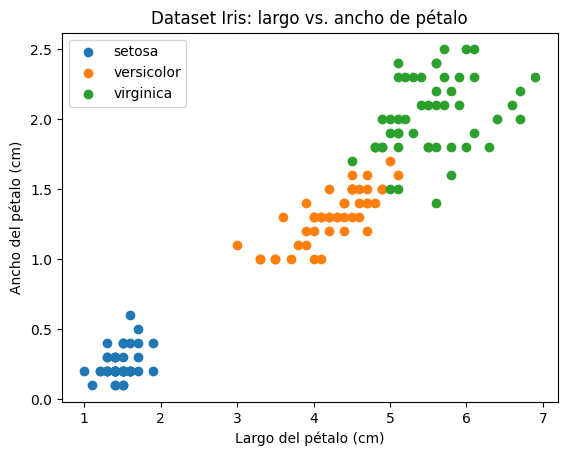

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
for especie, grupo in df.groupby("especie"):
    ax.scatter(grupo["petal length (cm)"], grupo["petal width (cm)"], label=especie)
ax.set_xlabel("Largo del pétalo (cm)")
ax.set_ylabel("Ancho del pétalo (cm)")
ax.set_title("Dataset Iris: largo vs. ancho de pétalo")
ax.legend()
plt.show()

Las tres especies (colores) se agrupan en zonas bastante distintas del gráfico. Esa estructura es justamente lo que un modelo de clasificación va a aprender a explotar.

## 3. Un vistazo al aprendizaje no supervisado

¿Qué pasa si escondemos las etiquetas de especie y le pedimos a un algoritmo que agrupe las flores sin decirle a qué especie pertenece cada una?

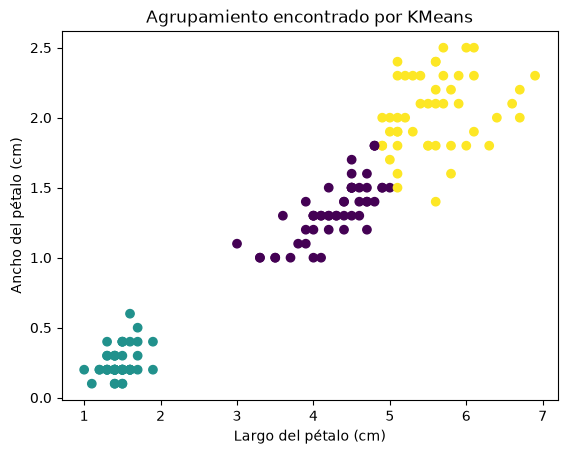

In [25]:
from sklearn.cluster import KMeans

X_iris = df[["petal length (cm)", "petal width (cm)"]]

kmeans = KMeans(n_clusters=3, random_state=0, n_init=10)
clusters = kmeans.fit_predict(X_iris)

fig, ax = plt.subplots()
scatter = ax.scatter(X_iris["petal length (cm)"], X_iris["petal width (cm)"], c=clusters, cmap="viridis")
ax.set_xlabel("Largo del pétalo (cm)")
ax.set_ylabel("Ancho del pétalo (cm)")
ax.set_title("Agrupamiento encontrado por KMeans")
plt.show()

Comparemos este gráfico con el anterior (donde coloreamos por especie real). El algoritmo encontró una separación muy parecida! El aprendizaje no supervisado encuentra patrones sin etiquetas.

## Ejercicios

**Ejercicio 1.** En la celda de la regla `es_spam_regla`, cambiá el umbral de 3 a otro valor y probá con distintos mails. ¿En qué casos falla tu intuición?

**Ejercicio 2.** Agregá 4 ejemplos nuevos al array `X`/`y` de la sección 1 (inventalos) y volvé a entrenar el modelo. ¿Cambia la predicción para `nuevo_mail = [[2, 2]]`?

**Ejercicio 3.** Usando el dataset `df` de Iris, hacé un gráfico de dispersión (`scatter`) pero con las columnas `sepal length (cm)` y `sepal width (cm)` en vez de las de pétalo. ¿Se separan igual de bien las especies? ¿Por qué te parece que pasa esto?

**Ejercicio 4 (para pensar).** Pensá un ejemplo de un problema del mundo real que se resolvería con aprendizaje supervisado, uno con no supervisado, y uno con aprendizaje por refuerzo. Justificá por qué cada uno corresponde a esa categoría.

In [ ]:
# Ejercicio 1: tu código acá
def es_spam_regla(cantidad_veces_gratis):
    return cantidad_veces_gratis >= 10

for veces in [0, 5, 4, 10, 1, 2, 4, 0.1]:
    print(veces, "->", es_spam_regla(veces))

 #¿Qué responder a la pregunta: "¿En qué casos falla tu intuición?"?

#El profe te hace esa pregunta para que veas por qué programar reglas a mano no sirve en la vida real:

#Si ponés un umbral muy bajo (ej: >= 1):
#Cualquier mail legítimo que use la palabra una sola vez (por ejemplo, un mail de tu facultad que diga "el taller del viernes es con entrada gratis") va a ser bloqueado como Spam por error (Falso Positivo).
#Si ponés un umbral muy alto (ej: >= 5):
#Un mail de estafa bien armado que diga "gratis" solo 3 veces pero esté lleno de links con virus se te va a escapar y va a entrar a tu bandeja (Falso Negativo).

#Conclusión: Una regla fija inventada por una persona a ojo nunca alcanza, porque el lenguaje es complejo. Por eso dejamos que Machine Learning mire muchas variables a la vez.

0 -> False
5 -> False
4 -> False
10 -> True
1 -> False
2 -> False
4 -> False
0.1 -> False


In [15]:
# Ejercicio 2: tu código acá
import numpy as np

# Puede ser: [cantidad de veces que aparece la palabra "gratis", cantidad de links del mail]
X = np.array([
    [0, 0],
    [1, 0],
    [0, 1],
    [4, 3],
    [5, 5],
    [3, 4],
    [0, 0],
    [6, 2],
    [6,7],
    [0,10],
    [1,2],
    [2,1],
])
y = np.array([0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0 ,1])  # 0 = no es spam, 1 = es spam

print("Features (X):\n", X)
print("Etiquetas (y):", y)

# Necesitamos scikit-learn. 
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression()
modelo.fit(X, y)

# Probamos con un mail nuevo: aparece "gratis" 2 veces y tiene 2 links
nuevo_mail = [[2, 2]]
prediccion = modelo.predict(nuevo_mail)
print("¿Es spam?", "Sí" if prediccion[0] == 1 else "No")

# Pedimos las probabilidades exactas
probabilidades = modelo.predict_proba(nuevo_mail)

# El primer número es clase 0 (No spam), el segundo es clase 1 (Sí spam)
prob_no_spam = probabilidades[0][0] * 100
prob_spam = probabilidades[0][1] * 100

print(f"Probabilidad de NO spam: {prob_no_spam:.1f}%")
print(f"Probabilidad de SÍ spam: {prob_spam:.1f}%")

Features (X):
 [[ 0  0]
 [ 1  0]
 [ 0  1]
 [ 4  3]
 [ 5  5]
 [ 3  4]
 [ 0  0]
 [ 6  2]
 [ 6  7]
 [ 0 10]
 [ 1  2]
 [ 2  1]]
Etiquetas (y): [0 0 0 1 1 1 0 1 1 1 0 1]
¿Es spam? Sí
Probabilidad de NO spam: 39.3%
Probabilidad de SÍ spam: 60.7%


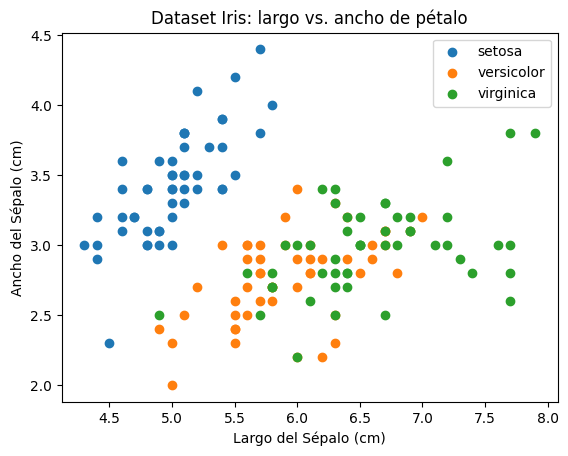

In [ ]:
# Ejercicio 3: tu código acá
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame
df["especie"] = df["target"].map(dict(enumerate(iris.target_names)))
df.head()

import matplotlib.pyplot as plt

fig, ax = plt.subplots()
for especie, grupo in df.groupby("especie"):
    ax.scatter(grupo["sepal length (cm)"], grupo["sepal width (cm)"], label=especie)
ax.set_xlabel("Largo del Sépalo (cm)")
ax.set_ylabel("Ancho del Sépalo (cm)")
ax.set_title("Dataset Iris: largo vs. ancho de pétalo")
ax.legend()
plt.show()


#"No se separan igual de bien. Mientras que con los pétalos las tres especies quedaban claramente aisladas, 
# con las medidas del sépalo las especies Versicolor (naranja) y Virginica (verde) quedan muy superpuestas 
# y mezcladas. Esto ocurre porque el sépalo de ambas especies tiene proporciones casi idénticas, lo que 
# demuestra que en Machine Learning algunas variables aportan ruido y no todas sirven para clasificar con precisión."  

### Ejercicio 4: Respuestas y Justificaciones

**1. Aprendizaje Supervisado:**
- **Problema del mundo real:** Predecir el precio de venta de autos usados (o evaluar si un cliente pagará un crédito bancario).
- **Justificación:** Contamos con un dataset histórico donde cada ejemplo tiene la respuesta correcta guardada de antemano (año, kilometraje, modelo y el **precio real** al que se vendió). El algoritmo aprende a asociar las características de entrada ($X$) con la etiqueta objetivo ($y$).

**2. Aprendizaje No Supervisado:**
- **Problema del mundo real:** Segmentación de usuarios en Spotify o clientes de una tienda según hábitos de consumo.
- **Justificación:** No tenemos etiquetas previas ni respuestas correctas anotadas (nadie definió a mano los 'tipos' de oyente). El algoritmo analiza únicamente las variables ($X$) y busca patrones geométricos y agrupamientos naturales (clusters) por similitud.

**3. Aprendizaje por Refuerzo:**
- **Problema del mundo real:** Optimización de refrigeración y consumo eléctrico en centros de cómputo (o semáforos inteligentes en una avenida).
- **Justificación:** No hay una planilla fija con respuestas. El modelo es un **agente** que interactúa paso a paso con un **entorno** dinámico mediante ensayo y error, recibiendo **recompensas** (premio por bajar el consumo eléctrico) y **castigos** (penalización si la temperatura sube de niveles seguros).

> **Conclusión metodológica:** La categoría de Machine Learning no se elige probando modelos al azar; viene determinada desde el día 1 por los datos que tenemos y el objetivo buscado.